In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import re

In [3]:
train_path = "../data/raw/train.csv"
test_path = "../data/raw/test.csv"

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

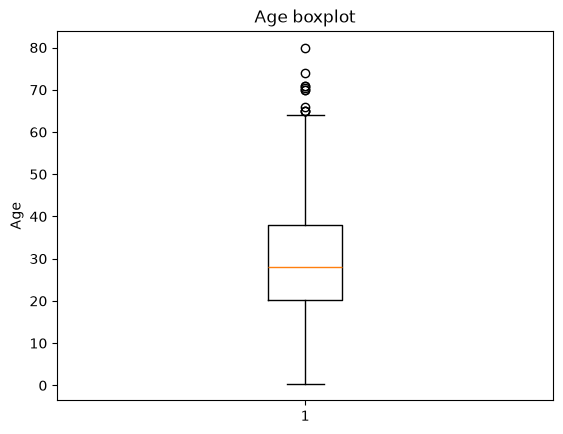

In [40]:
# Изучение выбросов
plt.boxplot(train['Age'].dropna())
plt.ylabel('Age')
plt.title('Age boxplot')
plt.show()

In [1]:
Q1 = train['Age'].quantile(0.25)
Q3 = train['Age'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
train[ train['Age'] > upper ].shape[0]

NameError: name 'train' is not defined

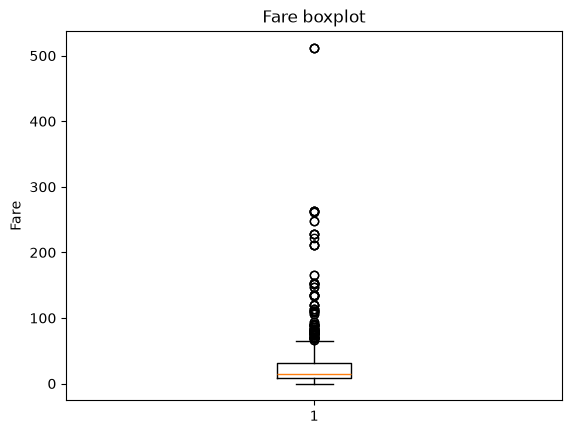

In [41]:
plt.boxplot(train['Fare'].dropna())
plt.ylabel('Fare')
plt.title('Fare boxplot')
plt.show()

In [59]:
Q1 = train['Fare'].quantile(0.25)
Q3 = train['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
#train[ train['Fare'] > upper ]

outliers = train[train['Fare'] > upper]

outliers['Fare'].describe()
outliers['Pclass'].value_counts()

Pclass
1    104
3      7
2      5
Name: count, dtype: int64

In [60]:
train.groupby('Pclass')['Fare'].describe()

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,216.0,84.154687,78.380373,0.0,30.92395,60.2875,93.5,512.3292
2,184.0,20.662183,13.417399,0.0,13.00000,14.2500,26.0,73.5000
3,491.0,13.675550,11.778142,0.0,7.75000,8.0500,15.5,69.5500


In [ ]:
train.sort_values('Fare', ascending=False)[
    ['Fare', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Survived', 'Ticket']
].head(10)

# Вероятно у людей с одинаковыми Ticket указан общий Fare на группу и имеет смысл разделить его на количество людей в группе

,Fare,Pclass,Sex,Age,SibSp,Parch,Survived,Ticket
679,512.3292,1,male,36.0,0,1,1,PC 17755
258,512.3292,1,female,35.0,0,0,1,PC 17755
737,512.3292,1,male,35.0,0,0,1,PC 17755
88,263.0000,1,female,23.0,3,2,1,19950
438,263.0000,1,male,64.0,1,4,0,19950
341,263.0000,1,female,24.0,3,2,1,19950
27,263.0000,1,male,19.0,3,2,0,19950
742,262.3750,1,female,21.0,2,2,1,PC 17608
311,262.3750,1,female,18.0,2,2,1,PC 17608
299,247.5208,1,female,50.0,0,1,1,PC 17558


In [65]:
train.groupby('Ticket')['Fare'].nunique().sort_values(ascending=False).head(10)

Ticket
7534         2
111426       1
WE/P 5735    1
110152       1
110413       1
110465       1
110564       1
110813       1
111240       1
113056       1
Name: Fare, dtype: int64

In [ ]:
train[ train['Ticket'] == '7534' ]
# Получили что это может быть просто ошибкой в данных, поэтому для данного тикета изменим Fare на среднее значение по классу, то есть на 9,53125

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
138,139,0,3,"Osen, Mr. Olaf Elon",male,16.0,0,0,7534,9.2167,NaN,S
876,877,0,3,"Gustafsson, Mr. Alfred Ossian",male,20.0,0,0,7534,9.8458,NaN,S


# EDA

In [103]:
train.describe(include = 'all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,ticket_size,Deck,Age_bin
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889,891.000000,891,714
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3,NaN,9,8
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S,NaN,Unknown,"(20, 30]"
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644,NaN,687,230
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN,1.787879,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN,1.361142,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN,1.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN,1.000000,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,1.000000,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN,2.000000,NaN,NaN


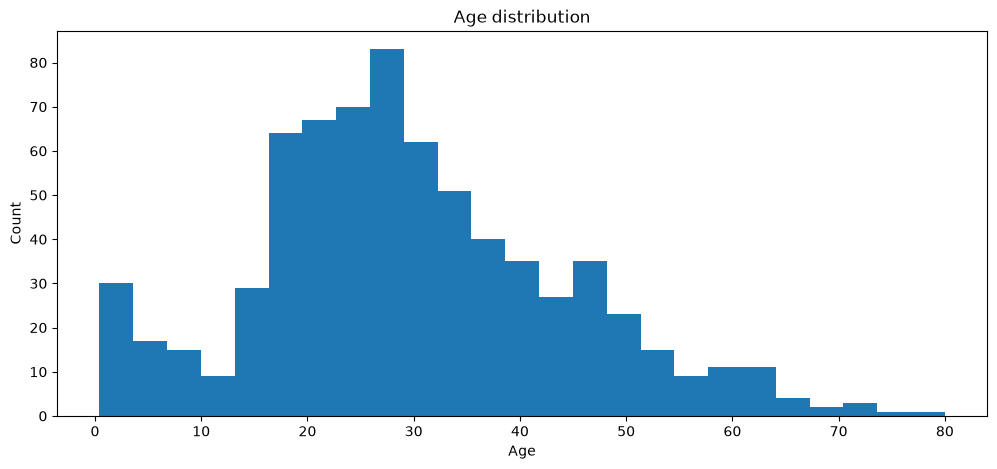

In [4]:
plt.figure(figsize=(12, 5))

plt.hist(train['Age'].dropna(), bins=25)

plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Age distribution')

plt.show()

In [ ]:
sex_counts = train['Sex'].value_counts()
plt.figure(figsize=(10, 6))
plt.bar(sex_counts.index, sex_counts.values)

plt.xlabel('Sex')
plt.ylabel('Count')
plt.title('Sex distribution')

plt.show()

In [ ]:
survival_by_class = train.groupby('Pclass')['Survived'].mean()

plt.bar(survival_by_class.index, survival_by_class.values)

plt.xlabel('Pclass')
plt.ylabel('Survival rate')
plt.title('Survival by class')

plt.show()

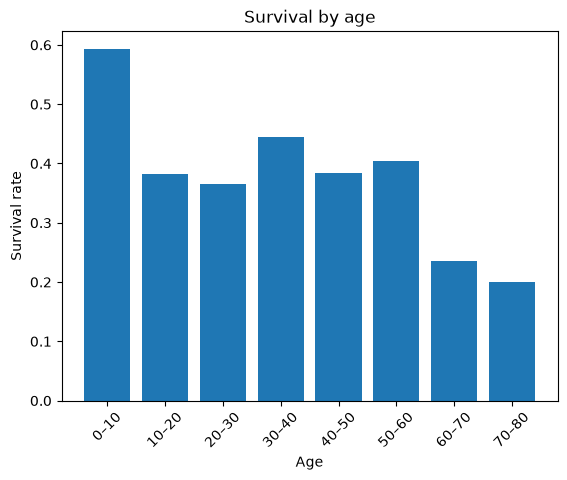

In [5]:
age_bin = pd.cut(train['Age'], bins=range(0, 91, 10))
survival_by_age = train.groupby(age_bin, observed=True)['Survived'].mean()

x_label = [f'{x.left}–{x.right}' for x in survival_by_age.index]

plt.bar(x_label, survival_by_age.values)
plt.xticks(rotation=45)
plt.xlabel('Age')
plt.ylabel('Survival rate')
plt.title('Survival by age')

plt.show()

# 2.1 Исследование

In [4]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Проверка на наличие константных фичей в данных
constant_features = train.columns[train.nunique() == 1]

constant_features

Index([], dtype='object')

In [6]:
target = 'Survived'

cat_features = ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']

num_features = [
    col for col in train.columns
    if col not in cat_features + [target]
]

In [7]:
train.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [27]:
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [28]:
train.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [81]:
train[train['Age'] >= 55] ['Survived'].mean()

np.float64(0.30952380952380953)

In [47]:
train[train['Fare'] <= 15] ['Survived'].mean()

np.float64(0.24890829694323144)

In [52]:
train[train['SibSp'] + train['Parch'] >= 1] ['Survived'].mean()

np.float64(0.5056497175141242)

In [54]:
train[train['SibSp'] + train['Parch'] > 0] ['Survived'].count()

np.int64(354)

In [55]:
train.groupby('Pclass')['Fare'].describe()

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,216.0,84.154687,78.380373,0.0,30.92395,60.2875,93.5,512.3292
2,184.0,20.662183,13.417399,0.0,13.00000,14.2500,26.0,73.5000
3,491.0,13.675550,11.778142,0.0,7.75000,8.0500,15.5,69.5500


In [60]:
train.groupby(['Sex', 'Pclass'])['Survived'].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

In [69]:
train[train['SibSp'] + train['Parch'] > 0].groupby('Sex')['Survived'].mean()

Sex
female    0.712766
male      0.271084
Name: Survived, dtype: float64

In [70]:
train[train['SibSp'] + train['Parch'] <= 0].groupby('Sex')['Survived'].mean()

Sex
female    0.785714
male      0.155718
Name: Survived, dtype: float64

In [71]:
train.groupby(['Sex', 'SibSp'])['Survived'].mean()

Sex     SibSp
female  0        0.787356
        1        0.754717
        2        0.769231
        3        0.363636
        4        0.333333
        5        0.000000
        8        0.000000
male    0        0.168203
        1        0.310680
        2        0.200000
        3        0.000000
        4        0.083333
        5        0.000000
        8        0.000000
Name: Survived, dtype: float64

In [73]:
train.groupby(['Sex', 'Parch'])['Survived'].mean()

Sex     Parch
female  0        0.788660
        1        0.766667
        2        0.612245
        3        0.750000
        4        0.000000
        5        0.250000
        6        0.000000
male    0        0.165289
        1        0.327586
        2        0.322581
        3        0.000000
        4        0.000000
        5        0.000000
Name: Survived, dtype: float64

In [86]:
train[train['Age'] < 20].groupby('Sex')['Survived'].mean()

Sex
female    0.706667
male      0.292135
Name: Survived, dtype: float64

In [112]:
train.groupby('Sex')['Age'].apply( lambda x: sum(x.isna()) / len(x) )

Sex
female    0.168790
male      0.214905
Name: Age, dtype: float64

In [114]:
train.groupby('Survived')['Age'].apply(lambda x: sum(x.isna()) / len(x))

Survived
0    0.227687
1    0.152047
Name: Age, dtype: float64

In [131]:
train.groupby(train['Age'].isna())['Survived'].mean()

Age
False    0.406162
True     0.293785
Name: Survived, dtype: float64

In [6]:
train.groupby([train['Age'].isna(), 'Pclass'])['Survived'].mean()
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Пропуски в Cabin

In [133]:
train.groupby(train['Cabin'].isna())['Survived'].mean()

Cabin
False    0.666667
True     0.299854
Name: Survived, dtype: float64

In [136]:
train.groupby([train['Cabin'].isna(), 'Pclass'])['Survived'].mean()

Cabin  Pclass
False  1         0.664773
       2         0.812500
       3         0.500000
True   1         0.475000
       2         0.440476
       3         0.235908
Name: Survived, dtype: float64

In [141]:
train.groupby(['Embarked', 'Pclass'])['Survived'].mean()

Embarked  Pclass
C         1         0.694118
          2         0.529412
          3         0.378788
Q         1         0.500000
          2         0.666667
          3         0.375000
S         1         0.582677
          2         0.463415
          3         0.189802
Name: Survived, dtype: float64

In [163]:
train['Name'].head()

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
Name: Name, dtype: object

In [8]:
def get_title(name):
    match = re.search(r',\s*([^\.]+)\.', name)
    return match.group(1) if match else 'Other'

In [9]:
train['Title'] = train['Name'].apply(get_title)
test['Title'] = test['Name'].apply(get_title)

train.groupby('Title')['Survived'].mean()

Title
Capt            0.000000
Col             0.500000
Don             0.000000
Dr              0.428571
Jonkheer        0.000000
Lady            1.000000
Major           0.500000
Master          0.575000
Miss            0.697802
Mlle            1.000000
Mme             1.000000
Mr              0.156673
Mrs             0.792000
Ms              1.000000
Rev             0.000000
Sir             1.000000
the Countess    1.000000
Name: Survived, dtype: float64

In [10]:
main_titles = ['Mr', 'Miss', 'Mrs', 'Master']

train['Title'] = train['Title'].where(
    train['Title'].isin(main_titles),
    'Other'
)
test['Title'] = test['Title'].where(
    test['Title'].isin(main_titles),
    'Other'
)

In [11]:
train.groupby('Title')['Survived'].mean()

Title
Master    0.575000
Miss      0.697802
Mr        0.156673
Mrs       0.792000
Other     0.444444
Name: Survived, dtype: float64

In [17]:
train.groupby('Title')['Age'].transform('median')
train['Age_missing'] = train['Age'].isna()

train['Age'].fillna(
    train.groupby('Title')['Age'].transform('median'),
    inplace=True
)

train[train['Age_missing'] == True].head()

C:\Users\anton\AppData\Local\Temp\ipykernel_21428\558337958.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train['Age'].fillna(


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_missing
5,6,0,3,"Moran, Mr. James",male,30.0,0,0,330877,8.4583,NaN,Q,Mr,True
17,18,1,2,"Williams, Mr. Charles Eugene",male,30.0,0,0,244373,13.0000,NaN,S,Mr,True
19,20,1,3,"Masselmani, Mrs. Fatima",female,35.0,0,0,2649,7.2250,NaN,C,Mrs,True
26,27,0,3,"Emir, Mr. Farred Chehab",male,30.0,0,0,2631,7.2250,NaN,C,Mr,True
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,21.0,0,0,330959,7.8792,NaN,Q,Miss,True


In [178]:
train.groupby('Title')['Age'].agg(['count', 'mean', 'median'])

,count,mean,median
Title,,,
Master,36,4.574167,3.5
Miss,146,21.773973,21.0
Mr,398,32.368090,30.0
Mrs,108,35.898148,35.0
Other,26,42.384615,44.5


In [186]:
train[ train['Age'].isna() ]['PassengerId'].count()

np.int64(177)

In [191]:
train[ train['Age'].isna() ].groupby('Title').count()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
Title,,,,,,,,,,,,
Master,4,4,4,4,4,0,4,4,4,4,0,4
Miss,36,36,36,36,36,0,36,36,36,36,2,36
Mr,119,119,119,119,119,0,119,119,119,119,12,119
Mrs,17,17,17,17,17,0,17,17,17,17,5,17
Other,1,1,1,1,1,0,1,1,1,1,0,1


In [ ]:
train['ticket_size'] = train.groupby('Ticket')['Ticket'].transform('size')
train.groupby('ticket_size')['Survived'].mean()

ticket_size
1    0.297989
2    0.574468
3    0.698413
4    0.500000
5    0.000000
6    0.000000
7    0.238095
Name: Survived, dtype: float64

In [9]:
train.groupby(['ticket_size','Sex'])['Survived'].mean()

ticket_size  Sex   
1            female    0.746269
             male      0.152542
2            female    0.813725
             male      0.290698
3            female    0.944444
             male      0.370370
4            female    0.592593
             male      0.352941
5            female    0.000000
             male      0.000000
6            female    0.000000
             male      0.000000
7            female    0.000000
             male      0.384615
Name: Survived, dtype: float64

In [52]:
train['Cabin'].dropna().str.findall(r'[A-Z]').explode().unique()

array(['C', 'E', 'G', 'D', 'A', 'B', 'F', 'T'], dtype=object)

In [54]:
sectors = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T']
def get_sector(cabin):
    if pd.isna(cabin):
        return 'Unknown'
    match = re.search(r'[A-Z]', cabin)
    return match.group(0)

train['Deck'] = train['Cabin'].apply(get_sector)

In [57]:
train.groupby(['Deck', 'Pclass'])['Survived'].mean()

Deck     Pclass
A        1         0.466667
B        1         0.744681
C        1         0.593220
D        1         0.758621
         2         0.750000
E        1         0.720000
         2         0.750000
         3         1.000000
F        2         0.875000
         3         0.200000
G        3         0.500000
T        1         0.000000
Unknown  1         0.475000
         2         0.440476
         3         0.235908
Name: Survived, dtype: float64